# 02 - Exploratory Data Analysis

Input: `data/processed/cleaned.csv`

## Imports

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
from pathlib import Path
from scipy.stats import f_oneway, ttest_ind

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

sns.set(style="darkgrid")

BASE = Path('.')
df = pd.read_csv(BASE / 'data' / 'processed' / 'cleaned.csv')
print(f"Loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()


Loaded: 24,750 rows x 42 columns


,age,gender,region,education,household_size,has_children,annual_income,tenure_months,membership_tier,preferred_channel,...,wishlist_items,support_tickets_90d,campaign_responses_6m,target_month,promo_planned_next_month,spend_next_month,snapshot_month,snapshot_quarter,snapshot_year,email_data_available
0,42,F,Suburban,High school,2,0,29400.0,40,Basic,Web,...,4,0,0,11,0,106.67,10,4,2024,1
1,26,F,Urban,Master,2,0,46200.0,72,Gold,App,...,1,0,1,11,1,296.00,10,4,2023,1
2,47,M,Urban,Bachelor,5,0,42500.0,33,Basic,App,...,2,0,0,3,1,121.78,2,1,2024,1
3,49,M,Suburban,Master,3,1,64500.0,35,Silver,App,...,3,0,2,9,1,367.96,8,3,2023,1
4,18,M,Suburban,Bachelor,4,1,44000.0,48,Silver,Web,...,2,0,1,12,0,165.40,11,4,2024,1


---
## 1. Target Variable — `spend_next_month`

### Distribution: Raw, Log-Scale and Box Plot

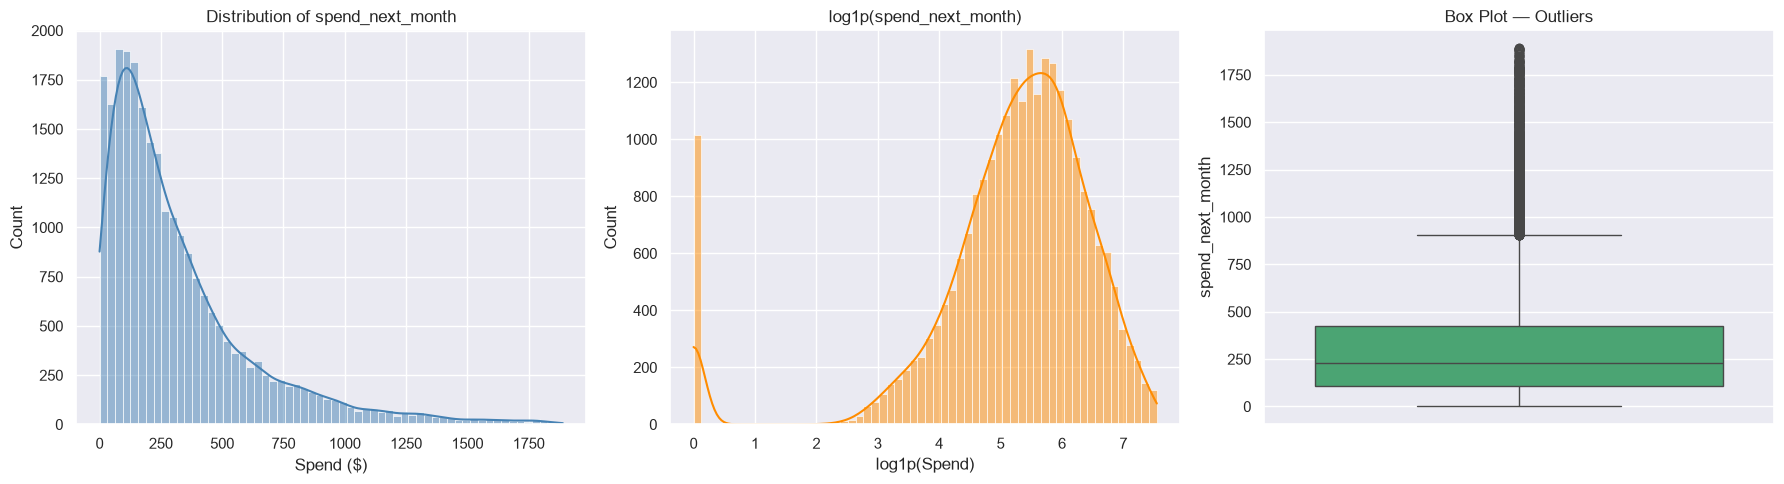

count    24750.000000
mean       322.556082
std        311.287258
min          0.000000
25%        108.842500
50%        227.380000
75%        427.272500
max       1889.250000

Skewness : 1.850
Kurtosis : 3.995


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['spend_next_month'], bins=60, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of spend_next_month')
axes[0].set_xlabel('Spend ($)')

sns.histplot(np.log1p(df['spend_next_month']), bins=60, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('log1p(spend_next_month)')
axes[1].set_xlabel('log1p(Spend)')

sns.boxplot(y=df['spend_next_month'], ax=axes[2], color='mediumseagreen')
axes[2].set_title('Box Plot — Outliers')

plt.tight_layout()
plt.show()

print(df['spend_next_month'].describe().to_string())
print(f"\nSkewness : {df['spend_next_month'].skew():.3f}")
print(f"Kurtosis : {df['spend_next_month'].kurtosis():.3f}")


### Zero-Spend Customer Analysis

Customers with spend_next_month = 0 : 1,015  (4.1%)

Zero vs Active spenders profile:
                          zero_mean  zero_median  active_mean  active_median
avg_spend_3m                 134.27        87.41       319.30         231.84
days_since_last_purchase      18.35        12.00         4.66           2.00
loyalty_points              1430.56       874.00      2343.45        1559.00
annual_income              43496.40     40800.00     45288.61       42100.00
orders_last_3m                12.20         9.00        29.28          24.00


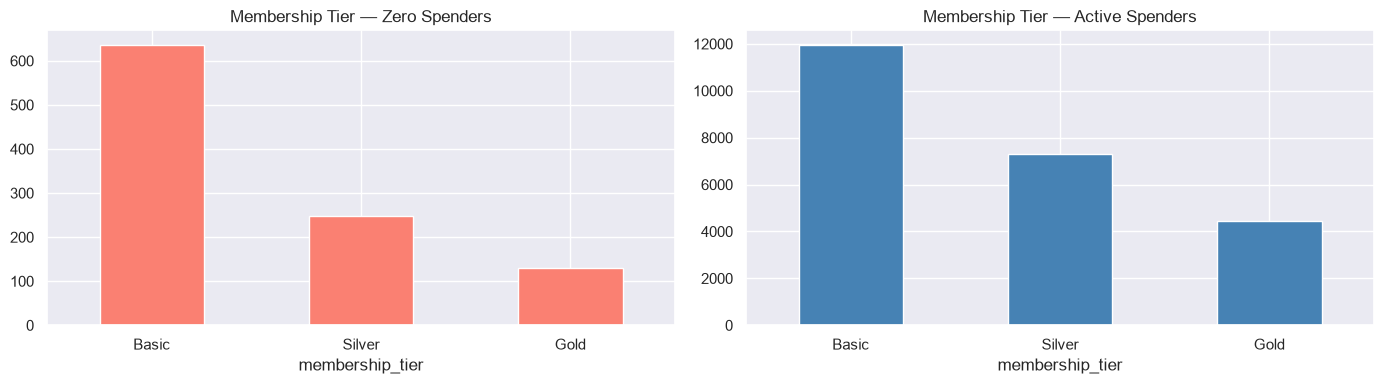

In [3]:
zero_mask = df['spend_next_month'] == 0
n_zero = zero_mask.sum()
print(f"Customers with spend_next_month = 0 : {n_zero:,}  ({n_zero / len(df) * 100:.1f}%)")

profile_cols = ['avg_spend_3m', 'days_since_last_purchase',
                'loyalty_points', 'annual_income', 'orders_last_3m']

comparison = pd.concat([
    df[zero_mask][profile_cols].describe().T[['mean', '50%']].rename(columns={'mean': 'zero_mean', '50%': 'zero_median'}),
    df[~zero_mask][profile_cols].describe().T[['mean', '50%']].rename(columns={'mean': 'active_mean', '50%': 'active_median'}),
], axis=1).round(2)
print("\nZero vs Active spenders profile:")
print(comparison.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df[zero_mask]['membership_tier'].value_counts().plot(kind='bar', ax=axes[0],
    color='salmon', title='Membership Tier — Zero Spenders')
df[~zero_mask]['membership_tier'].value_counts().plot(kind='bar', ax=axes[1],
    color='steelblue', title='Membership Tier — Active Spenders')
for ax in axes:
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()


### High-Spender Deep-Dive (Top 1%)

In [4]:
threshold = df['spend_next_month'].quantile(0.99)
high      = df[df['spend_next_month'] >= threshold]
rest      = df[df['spend_next_month'] <  threshold]

print(f"Top 1% threshold : ${threshold:,.2f}")
print(f"High-spenders    : {len(high):,} customers")

compare_cols = ['annual_income', 'tenure_months', 'loyalty_points',
                'orders_last_6m', 'avg_spend_6m']
comp = pd.DataFrame({
    'High Spenders (top 1%)': high[compare_cols].mean(),
    'Rest (bottom 99%)':      rest[compare_cols].mean()
}).round(2)
print("\n", comp.to_string())


Top 1% threshold : $1,489.71
High-spenders    : 248 customers

                 High Spenders (top 1%)  Rest (bottom 99%)
annual_income                 68137.10           44983.10
tenure_months                    30.71              30.82
loyalty_points                10772.31            2220.32
orders_last_6m                  161.96              55.92
avg_spend_6m                   1288.98             301.03


---
## 2. Spend by Demographics

### Bar Charts (Mean ± SD) and Box Plots per Category

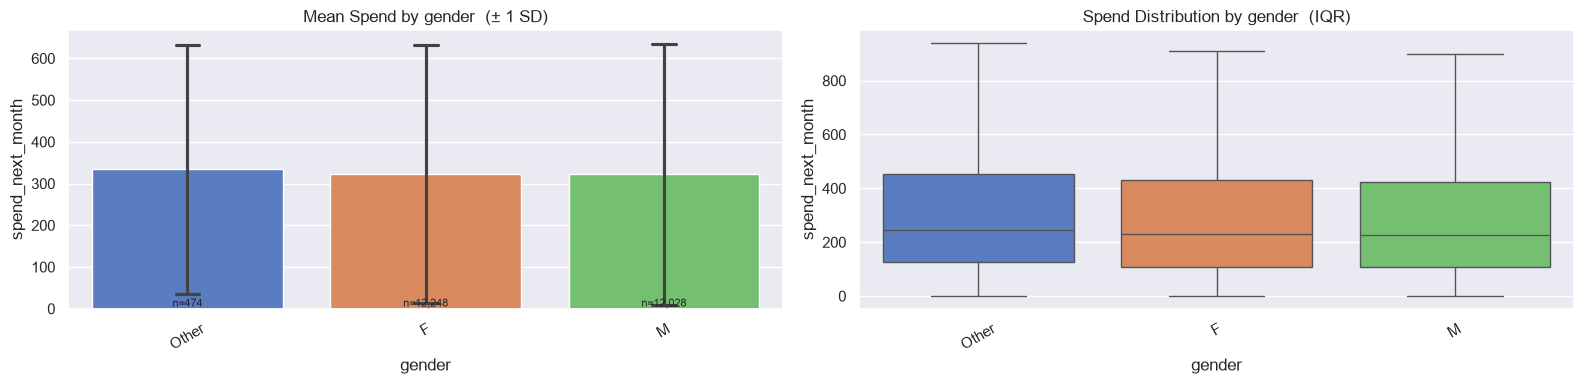

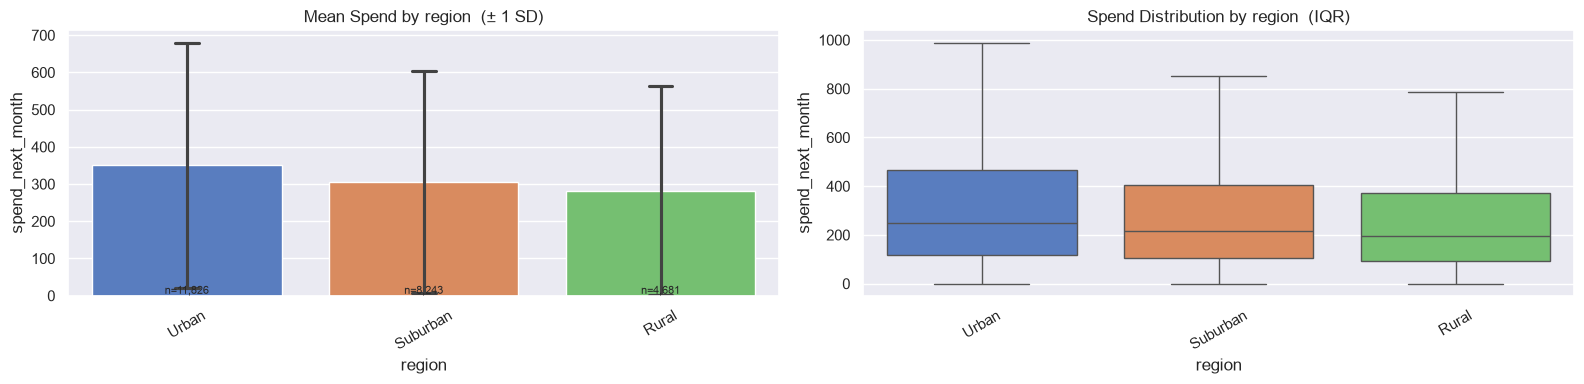

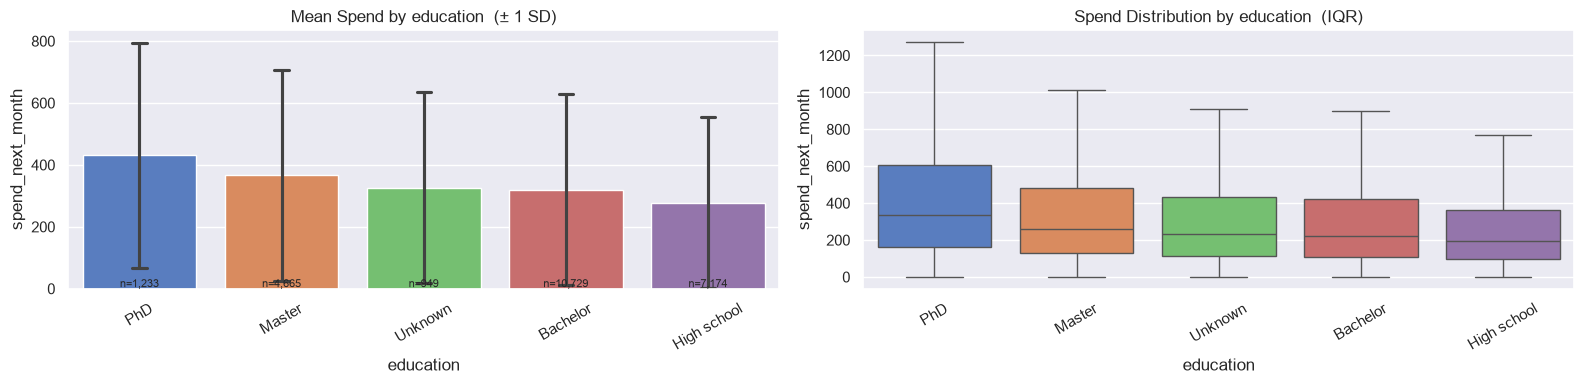

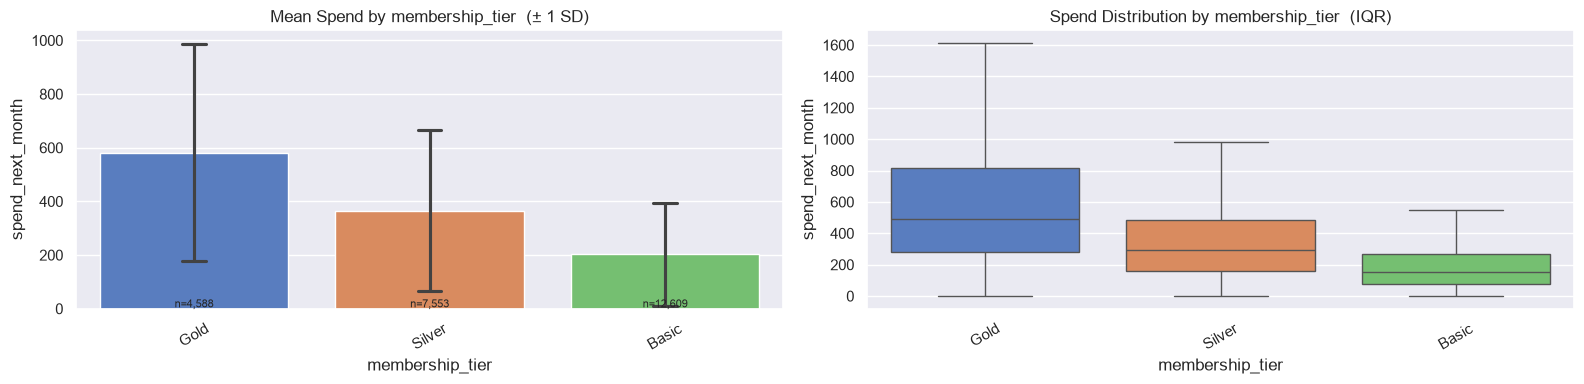

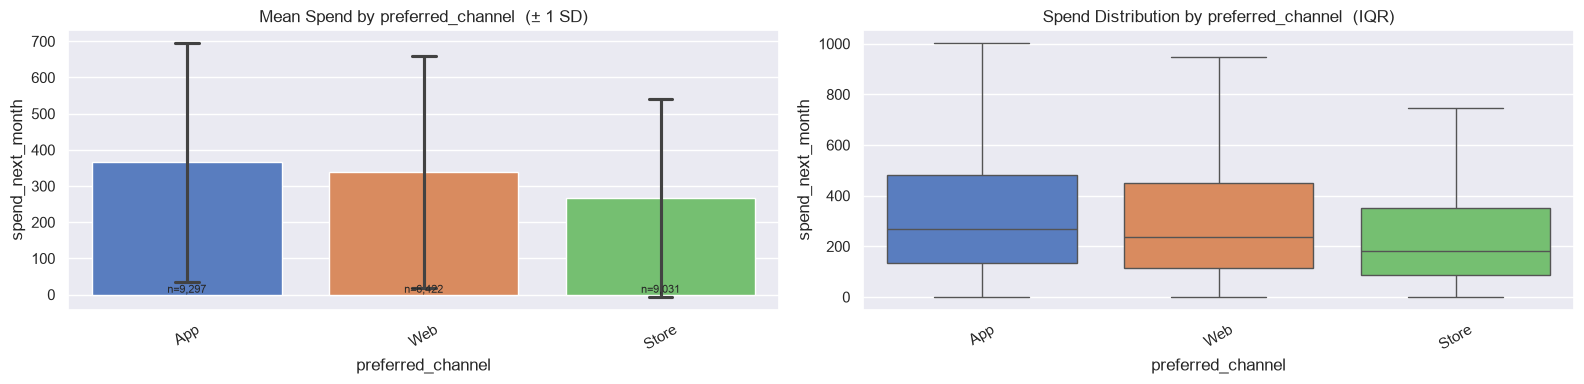

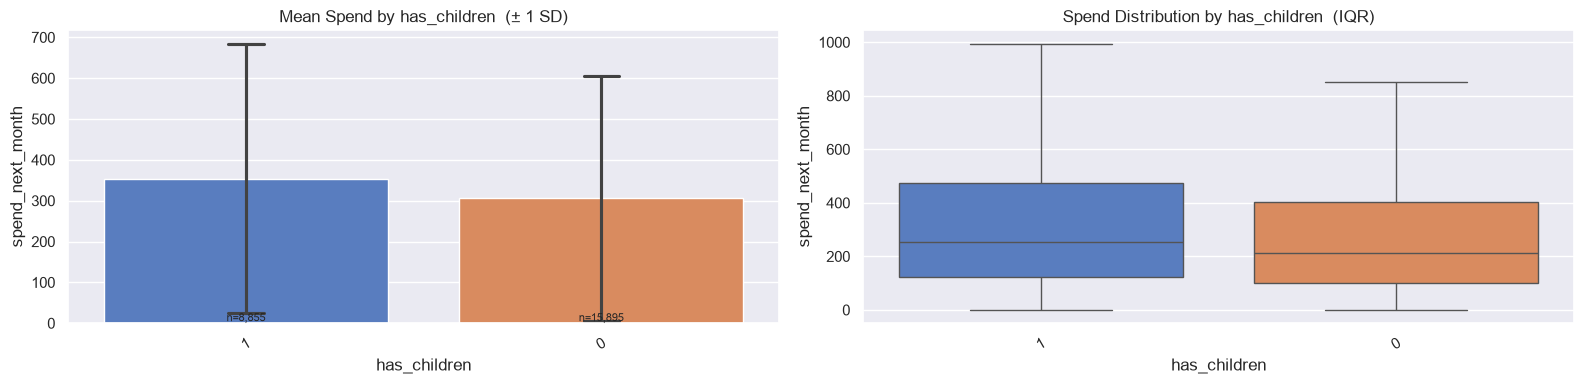

In [5]:
cat_cols = ['gender', 'region', 'education',
            'membership_tier', 'preferred_channel', 'has_children']

for col in cat_cols:
    order = df.groupby(col)['spend_next_month'].mean().sort_values(ascending=False).index

    fig, axes = plt.subplots(1, 2, figsize=(16, 4))

    sns.barplot(data=df, x=col, y='spend_next_month', order=order,
                errorbar='sd', ax=axes[0], palette='muted', capsize=0.1)
    axes[0].set_title(f'Mean Spend by {col}  (± 1 SD)')
    axes[0].tick_params(axis='x', rotation=30)

    # annotate with counts
    counts = df[col].value_counts()
    for i, cat in enumerate(order):
        axes[0].text(i, 5, f'n={counts.get(cat, 0):,}', ha='center', fontsize=8)

    sns.boxplot(data=df, x=col, y='spend_next_month', order=order,
                ax=axes[1], palette='muted', showfliers=False)
    axes[1].set_title(f'Spend Distribution by {col}  (IQR)')
    axes[1].tick_params(axis='x', rotation=30)

    plt.tight_layout()
    plt.show()


### Statistical Significance Tests (ANOVA & t-test)

In [6]:
test_results = []

for col in ['gender', 'region', 'education', 'membership_tier', 'preferred_channel']:
    groups = [g['spend_next_month'].values for _, g in df.groupby(col)]
    f_stat, p_val = f_oneway(*groups)
    test_results.append({'column': col, 'test': 'One-way ANOVA',
                         'statistic': round(f_stat, 3), 'p_value': round(p_val, 5),
                         'significant': 'YES' if p_val < 0.05 else 'NO'})

for col in ['has_children', 'promo_planned_next_month', 'email_subscribed', 'push_enabled']:
    g0 = df[df[col] == 0]['spend_next_month']
    g1 = df[df[col] == 1]['spend_next_month']
    t_stat, p_val = ttest_ind(g0, g1)
    test_results.append({'column': col, 'test': 't-test',
                         'statistic': round(t_stat, 3), 'p_value': round(p_val, 5),
                         'significant': 'YES' if p_val < 0.05 else 'NO'})

print(pd.DataFrame(test_results).to_string(index=False))


                  column          test  statistic  p_value significant
                  gender One-way ANOVA      0.353  0.70248          NO
                  region One-way ANOVA     97.302  0.00000         YES
               education One-way ANOVA     97.285  0.00000         YES
         membership_tier One-way ANOVA   3300.262  0.00000         YES
       preferred_channel One-way ANOVA    241.411  0.00000         YES
            has_children        t-test    -11.657  0.00000         YES
promo_planned_next_month        t-test    -21.433  0.00000         YES
        email_subscribed        t-test    -10.114  0.00000         YES
            push_enabled        t-test    -11.329  0.00000         YES


---
## 3. Numeric Features vs Target

### Hexbin Scatter Plots

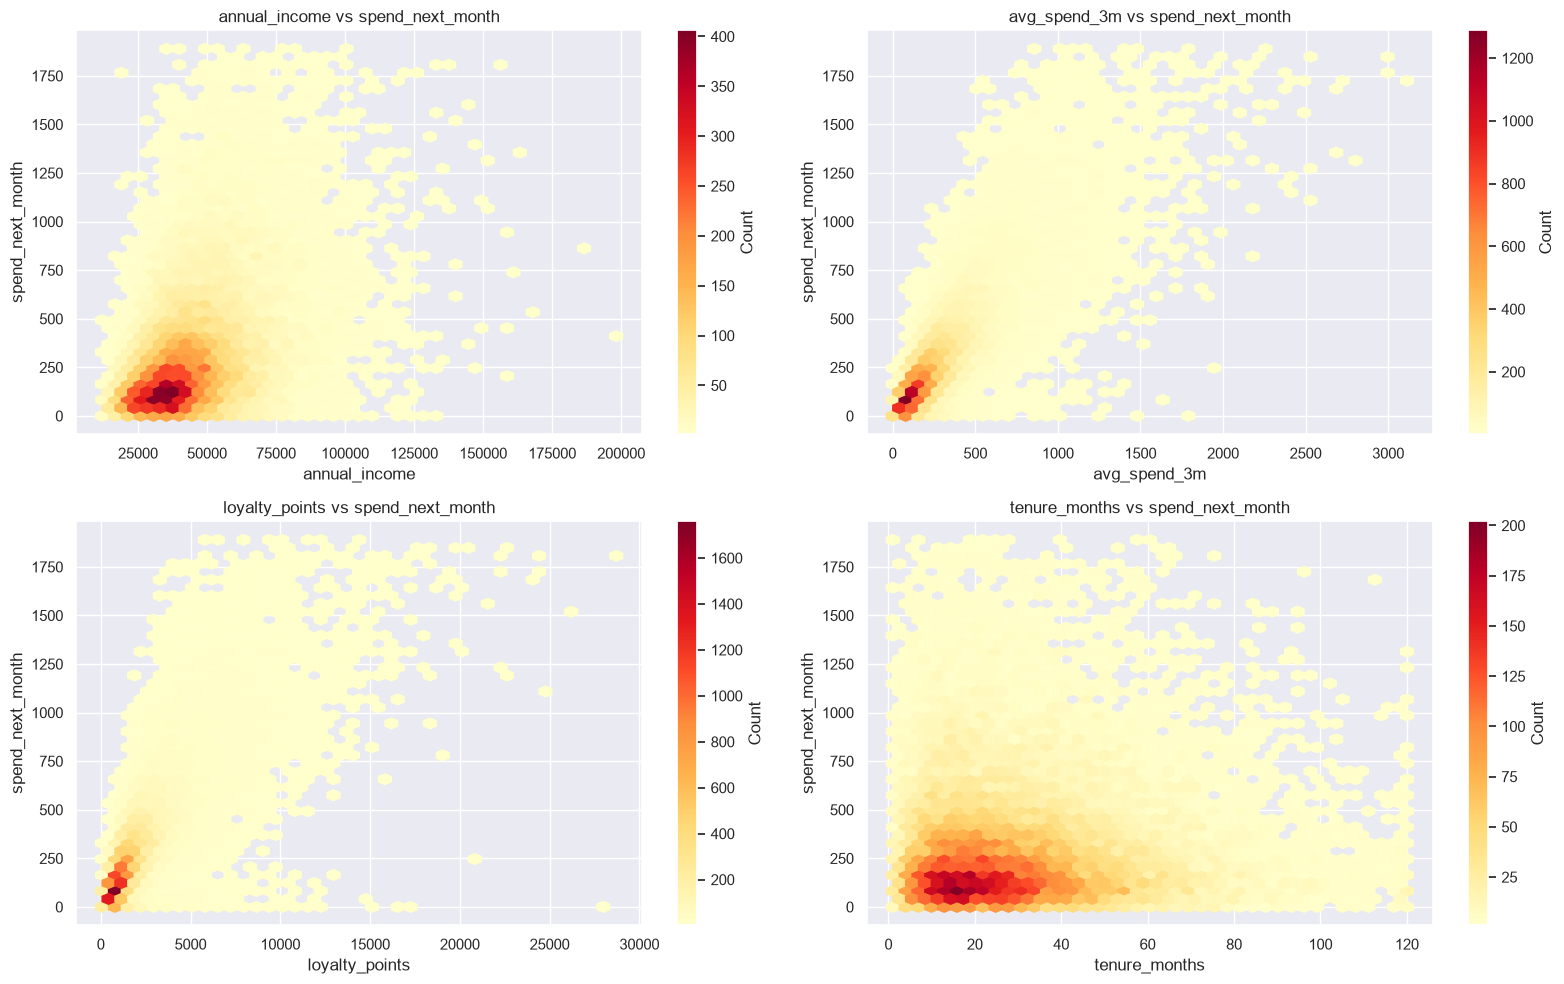

In [7]:
scatter_pairs = [
    ('annual_income',  'spend_next_month'),
    ('avg_spend_3m',   'spend_next_month'),
    ('loyalty_points', 'spend_next_month'),
    ('tenure_months',  'spend_next_month'),
]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, (xcol, ycol) in zip(axes.flatten(), scatter_pairs):
    hb = ax.hexbin(df[xcol], df[ycol], gridsize=40, cmap='YlOrRd', mincnt=1)
    plt.colorbar(hb, ax=ax, label='Count')
    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.set_title(f'{xcol} vs {ycol}')
plt.tight_layout()
plt.show()


### Pearson and Spearman Correlation with Target

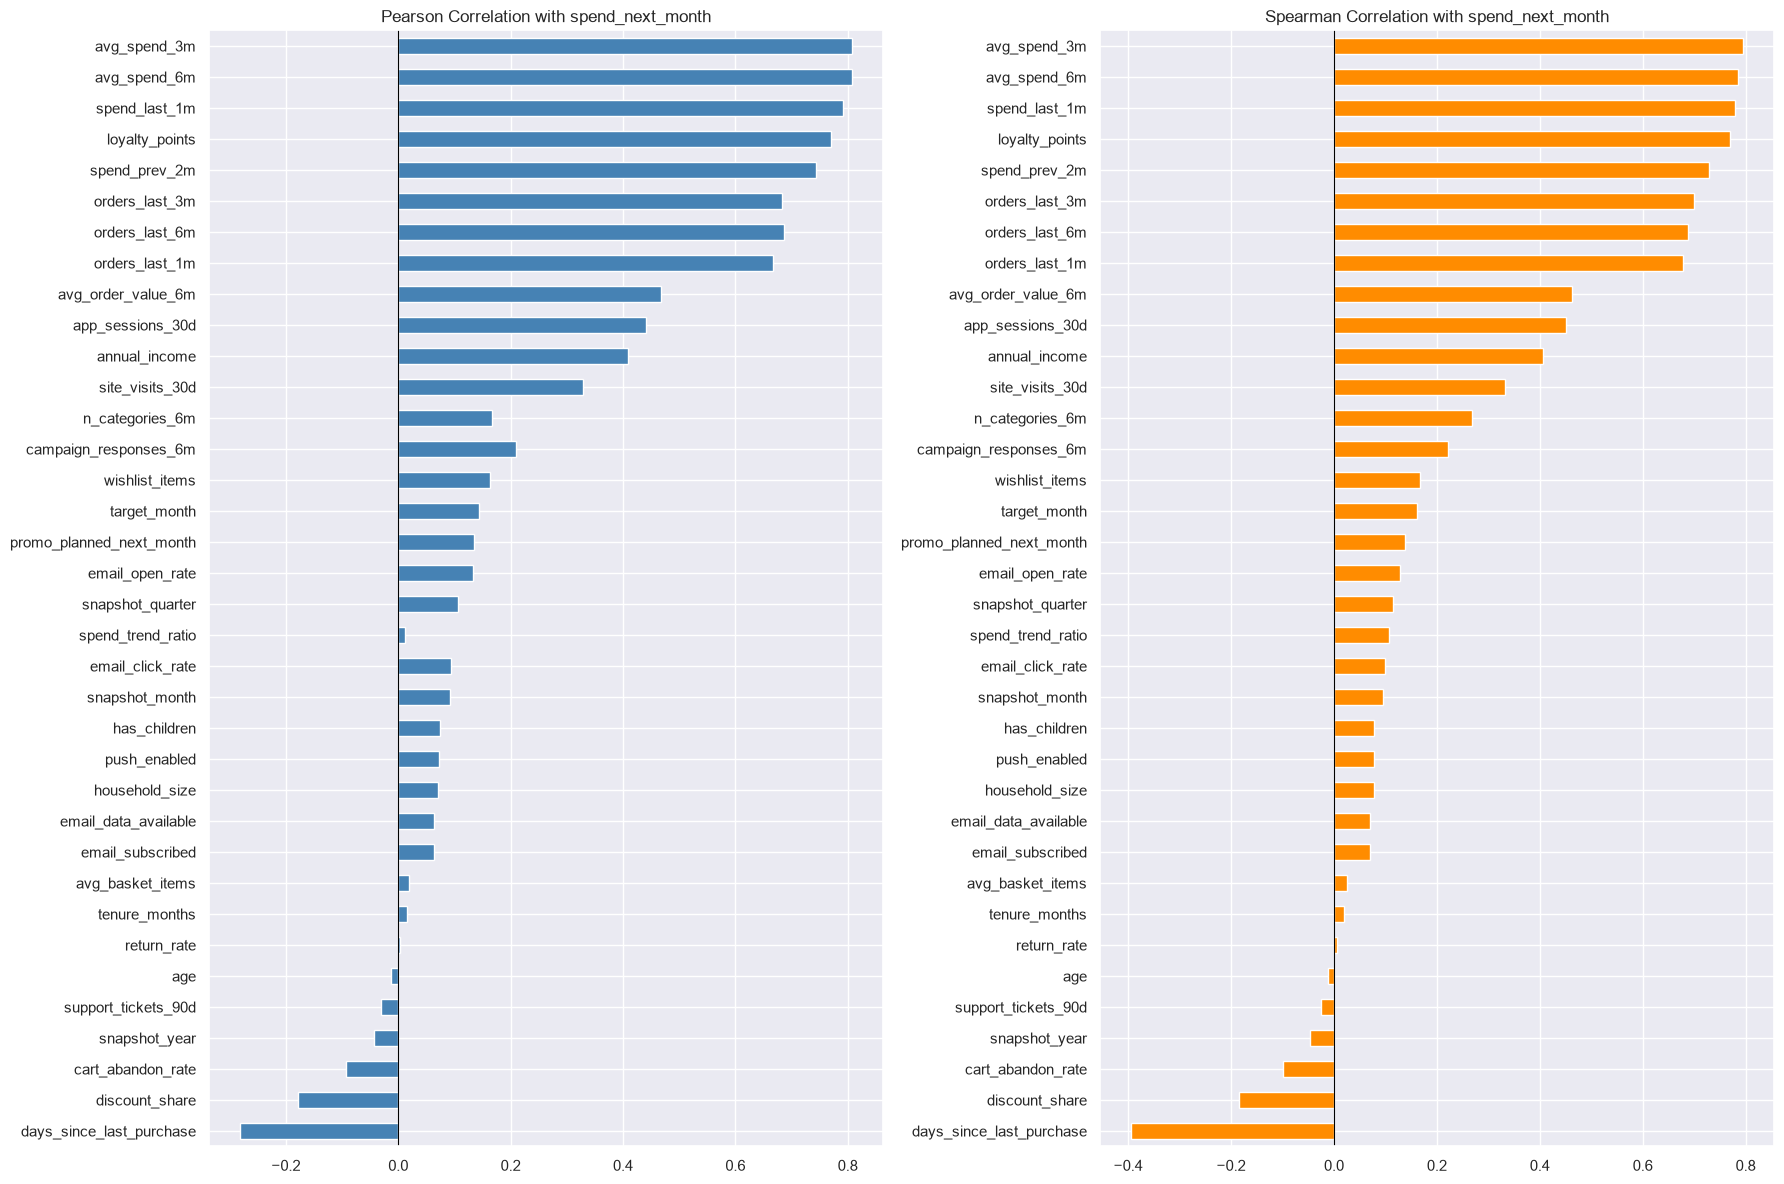

Top 10 features by |Spearman| correlation:
avg_spend_3m          0.795592
avg_spend_6m          0.784682
spend_last_1m         0.779463
loyalty_points        0.768763
spend_prev_2m         0.729523
orders_last_3m        0.698894
orders_last_6m        0.688906
orders_last_1m        0.678485
avg_order_value_6m    0.462118
app_sessions_30d      0.450253


In [8]:
numeric_df = df.select_dtypes(include='number').drop(columns=['spend_next_month'])

pearson  = numeric_df.corrwith(df['spend_next_month'], method='pearson').rename('Pearson')
spearman = numeric_df.corrwith(df['spend_next_month'], method='spearman').rename('Spearman')
corr_comparison = pd.concat([pearson, spearman], axis=1).sort_values('Spearman')

fig, axes = plt.subplots(1, 2, figsize=(18, 12))

corr_comparison['Pearson'].plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Pearson Correlation with spend_next_month')
axes[0].axvline(0, color='black', linewidth=0.8)

corr_comparison['Spearman'].plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title('Spearman Correlation with spend_next_month')
axes[1].axvline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.show()

print("Top 10 features by |Spearman| correlation:")
print(corr_comparison['Spearman'].abs().sort_values(ascending=False).head(10).to_string())


---
## 4. Multicollinearity Check

### Spearman Correlation Heatmap (Top 20 Features)

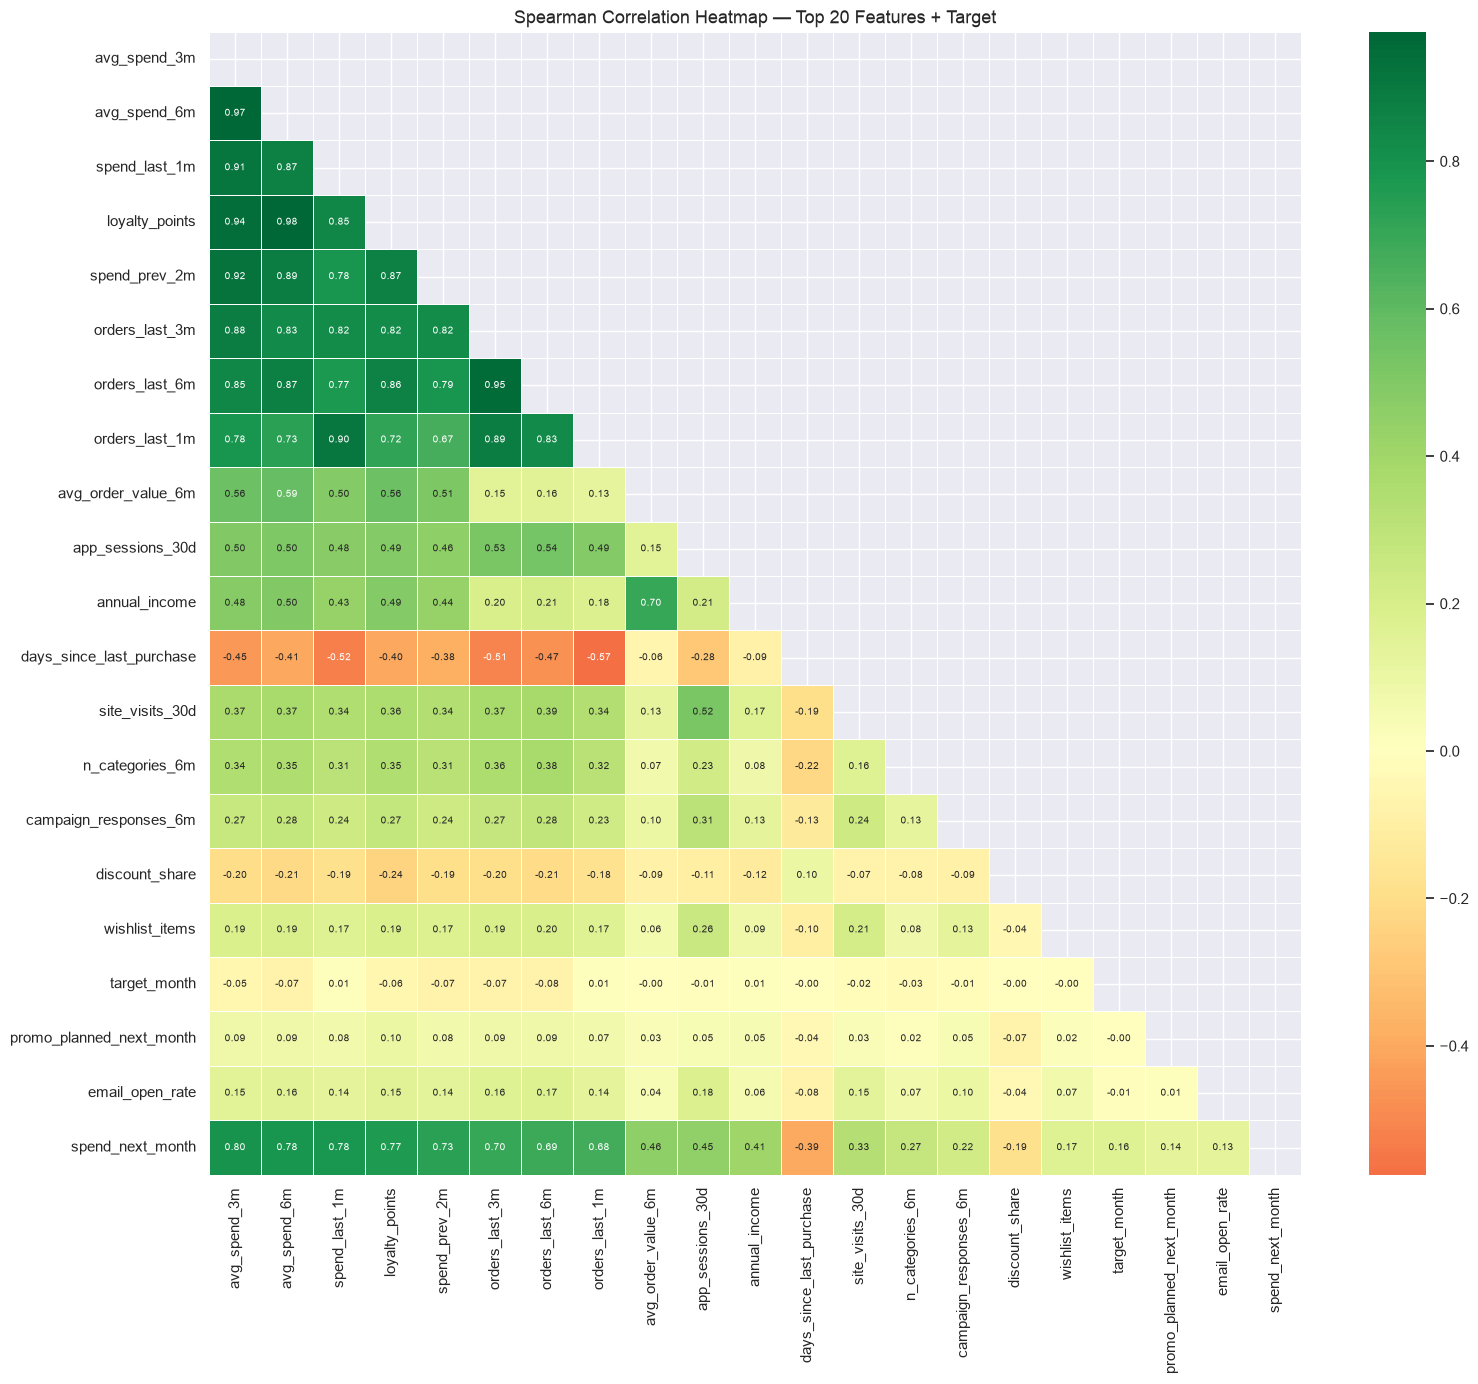

Feature pairs with |correlation| > 0.85:
     feature_1      feature_2  corr
  avg_spend_6m loyalty_points 0.976
  avg_spend_3m   avg_spend_6m 0.966
orders_last_3m orders_last_6m 0.954
  avg_spend_3m loyalty_points 0.942
  avg_spend_3m  spend_prev_2m 0.925
  avg_spend_3m  spend_last_1m 0.912
 spend_last_1m orders_last_1m 0.904
  avg_spend_6m  spend_prev_2m 0.890
orders_last_3m orders_last_1m 0.890
  avg_spend_3m orders_last_3m 0.882
  avg_spend_6m orders_last_6m 0.874
  avg_spend_6m  spend_last_1m 0.869
loyalty_points  spend_prev_2m 0.868
loyalty_points orders_last_6m 0.863


In [9]:
top_features = (
    corr_comparison['Spearman'].abs()
    .sort_values(ascending=False)
    .head(20).index.tolist()
)
top_features.append('spend_next_month')

corr_matrix = df[top_features].corr(method='spearman')

fig, ax = plt.subplots(figsize=(16, 14))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, linewidths=0.5, ax=ax, annot_kws={"size": 7})
ax.set_title('Spearman Correlation Heatmap — Top 20 Features + Target', fontsize=13)
plt.tight_layout()
plt.show()

print("Feature pairs with |correlation| > 0.85:")
high_corr = []
cols = corr_matrix.columns.tolist()
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        val = corr_matrix.iloc[i, j]
        if abs(val) > 0.85 and cols[j] != 'spend_next_month':
            high_corr.append({'feature_1': cols[i], 'feature_2': cols[j], 'corr': round(val, 3)})

if high_corr:
    print(pd.DataFrame(high_corr).sort_values('corr', ascending=False).to_string(index=False))
else:
    print("None found (excluding target).")


---
## 5. Recency, Seasonality and Promo

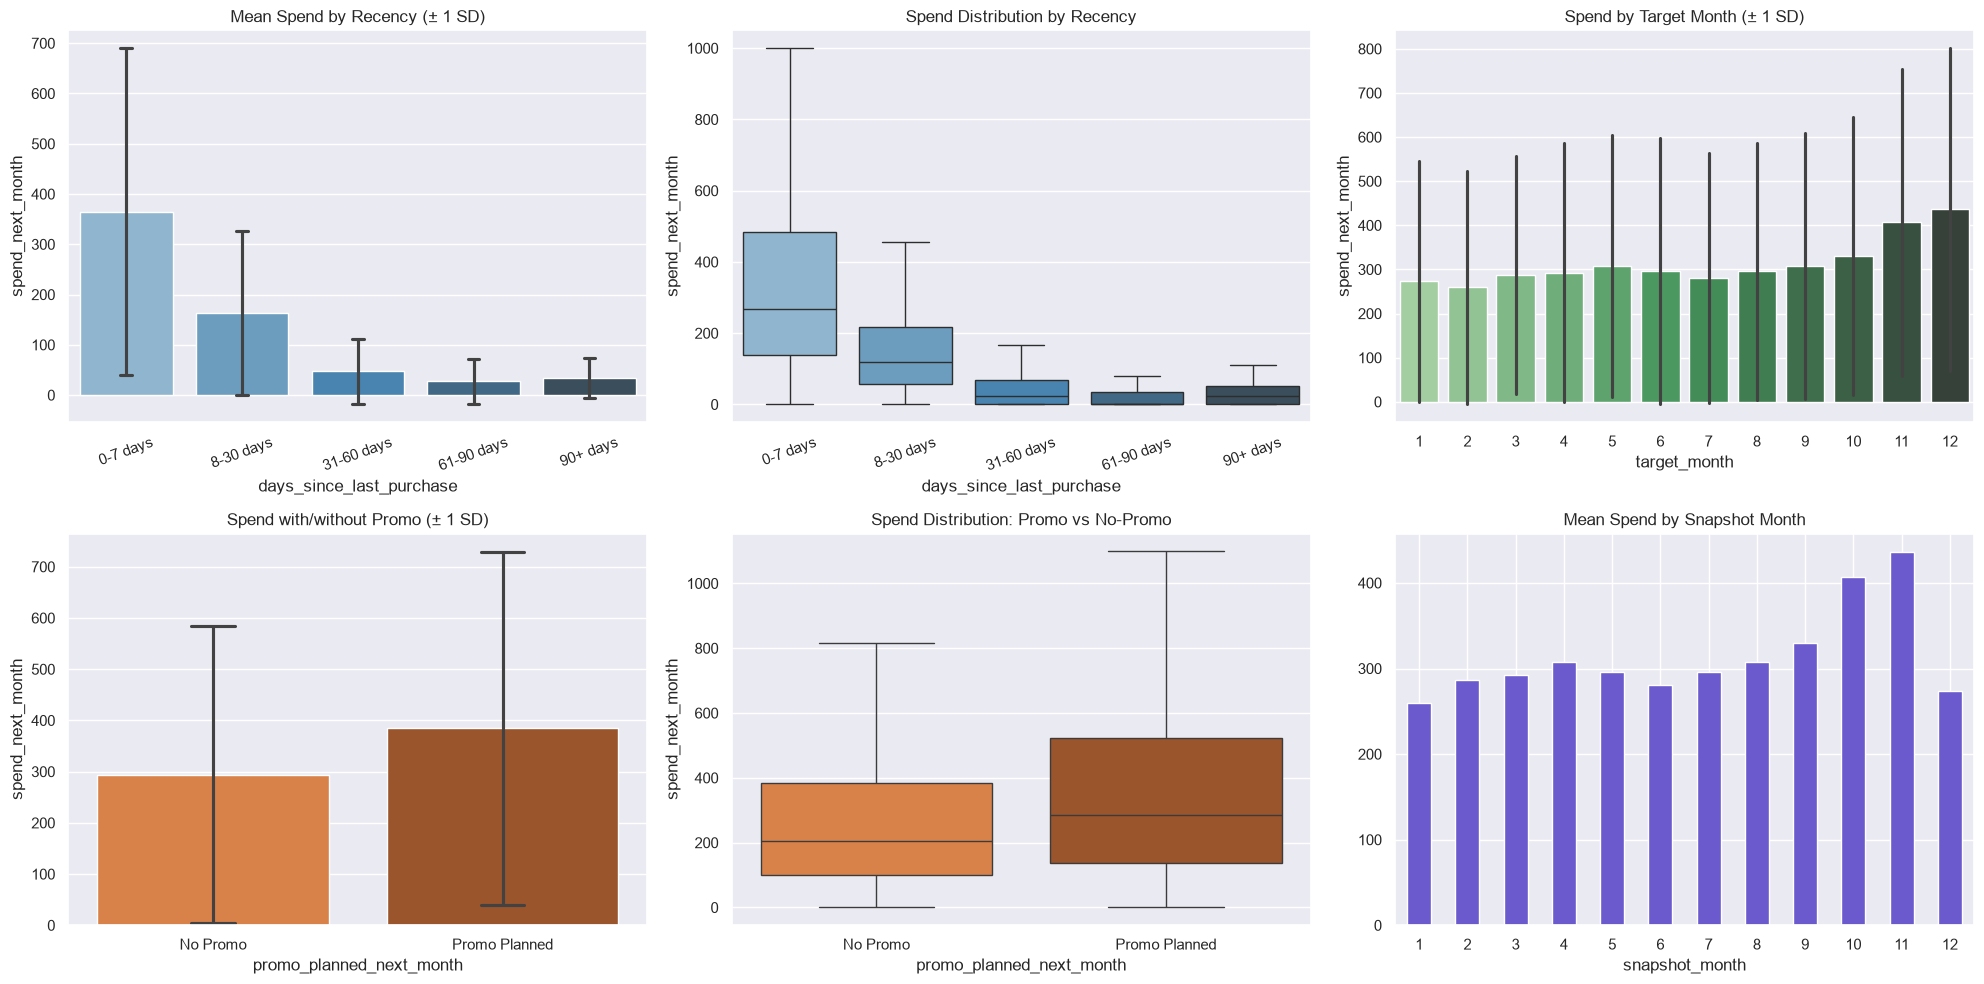

Promo lift: +$90.38 mean spend
t-test    : t=21.433, p=5.41e-101  ->  Significant (p < 0.05)


In [10]:
recency_group = pd.cut(
    df['days_since_last_purchase'], [-1, 7, 30, 60, 90, 999],
    labels=['0-7 days', '8-30 days', '31-60 days', '61-90 days', '90+ days']
)

fig, axes = plt.subplots(2, 3, figsize=(20, 10))

# Recency bar + box
sns.barplot(x=recency_group, y=df['spend_next_month'],
            ax=axes[0][0], errorbar='sd', palette='Blues_d', capsize=0.1)
axes[0][0].set_title('Mean Spend by Recency (± 1 SD)')
axes[0][0].tick_params(axis='x', rotation=20)

sns.boxplot(x=recency_group, y=df['spend_next_month'],
            ax=axes[0][1], palette='Blues_d', showfliers=False)
axes[0][1].set_title('Spend Distribution by Recency')
axes[0][1].tick_params(axis='x', rotation=20)

# Target month
sns.barplot(data=df, x='target_month', y='spend_next_month',
            ax=axes[0][2], errorbar='sd', palette='Greens_d')
axes[0][2].set_title('Spend by Target Month (± 1 SD)')

# Promo bar + box
sns.barplot(data=df, x='promo_planned_next_month', y='spend_next_month',
            ax=axes[1][0], errorbar='sd', capsize=0.15, palette='Oranges_d')
axes[1][0].set_title('Spend with/without Promo (± 1 SD)')
axes[1][0].set_xticklabels(['No Promo', 'Promo Planned'])

sns.boxplot(data=df, x='promo_planned_next_month', y='spend_next_month',
            ax=axes[1][1], palette='Oranges_d', showfliers=False)
axes[1][1].set_title('Spend Distribution: Promo vs No-Promo')
axes[1][1].set_xticklabels(['No Promo', 'Promo Planned'])

# Snapshot month (from preprocessing)
if 'snapshot_month' in df.columns:
    df.groupby('snapshot_month')['spend_next_month'].mean().plot(
        kind='bar', ax=axes[1][2], color='slateblue', edgecolor='white')
    axes[1][2].set_title('Mean Spend by Snapshot Month')
    axes[1][2].tick_params(axis='x', rotation=0)
else:
    axes[1][2].text(0.5, 0.5, 'snapshot_month not in data', ha='center', va='center')

plt.tight_layout()
plt.show()

# Promo significance test
promo_yes = df[df['promo_planned_next_month'] == 1]['spend_next_month']
promo_no  = df[df['promo_planned_next_month'] == 0]['spend_next_month']
t, p = ttest_ind(promo_yes, promo_no)
lift = promo_yes.mean() - promo_no.mean()
print(f"Promo lift: +${lift:.2f} mean spend")
print(f"t-test    : t={t:.3f}, p={p:.2e}  ->  {'Significant (p < 0.05)' if p < 0.05 else 'Not significant'}")


---
## 6. Segment Analysis — Per Membership Tier

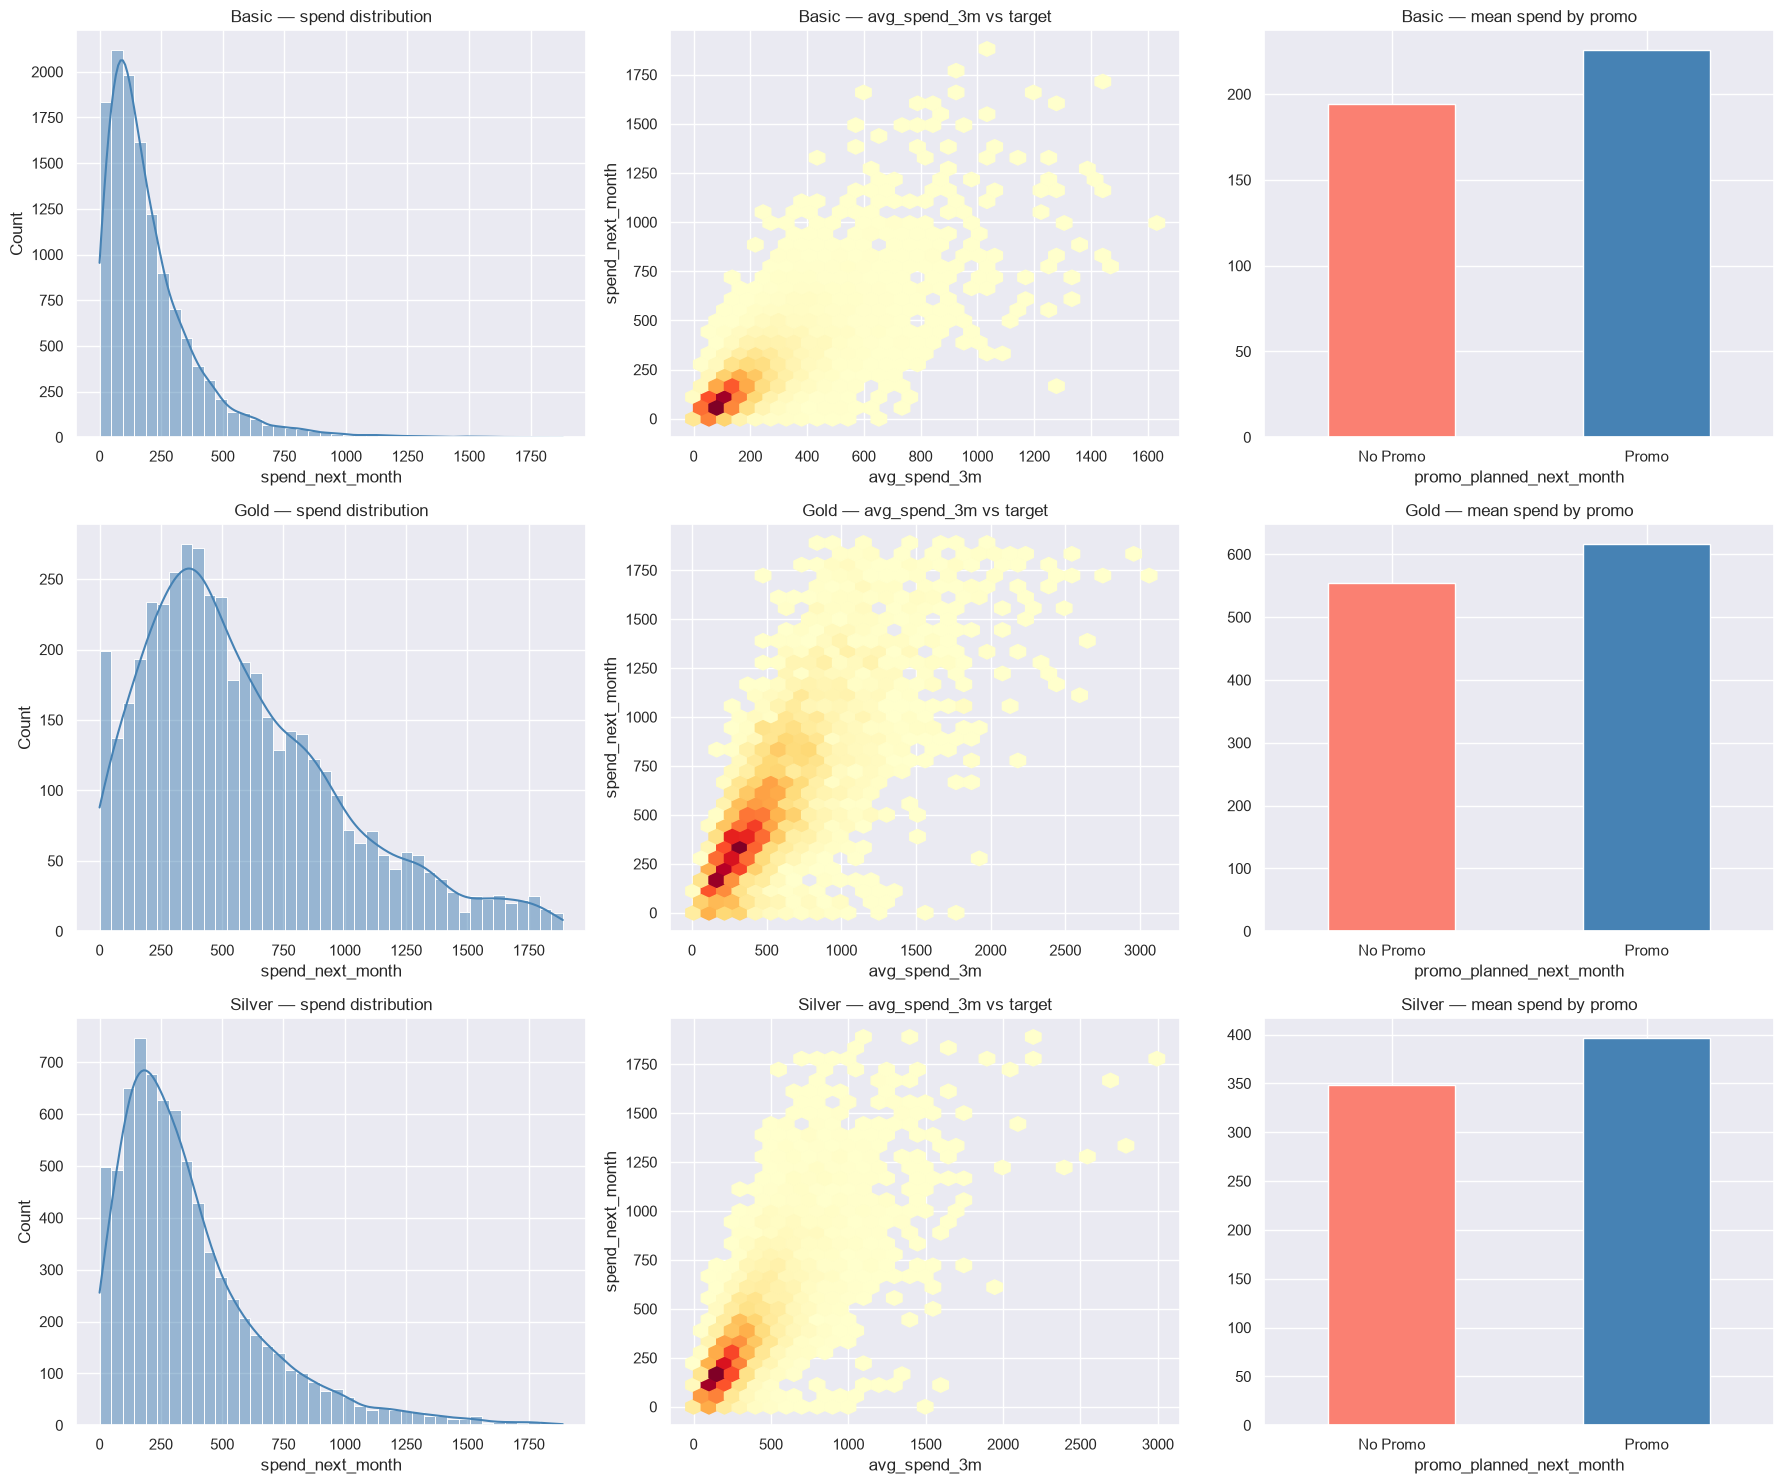

Promo lift significance per membership tier:
  Basic    : lift=+$31.32   p=0.0000   Significant
  Gold     : lift=+$61.54   p=0.0000   Significant
  Silver   : lift=+$47.95   p=0.0000   Significant


In [11]:
tiers = sorted(df['membership_tier'].unique())
fig, axes = plt.subplots(len(tiers), 3, figsize=(18, 5 * len(tiers)))

for row, tier in enumerate(tiers):
    sub = df[df['membership_tier'] == tier]

    sns.histplot(sub['spend_next_month'], bins=40, kde=True,
                 ax=axes[row][0], color='steelblue')
    axes[row][0].set_title(f'{tier} — spend distribution')

    axes[row][1].hexbin(sub['avg_spend_3m'], sub['spend_next_month'],
                        gridsize=30, cmap='YlOrRd', mincnt=1)
    axes[row][1].set_xlabel('avg_spend_3m')
    axes[row][1].set_ylabel('spend_next_month')
    axes[row][1].set_title(f'{tier} — avg_spend_3m vs target')

    tier_promo = sub.groupby('promo_planned_next_month')['spend_next_month'].mean()
    tier_promo.plot(kind='bar', ax=axes[row][2], color=['salmon', 'steelblue'])
    axes[row][2].set_title(f'{tier} — mean spend by promo')
    axes[row][2].set_xticklabels(['No Promo', 'Promo'], rotation=0)

plt.tight_layout()
plt.show()

print("Promo lift significance per membership tier:")
for tier in tiers:
    sub = df[df['membership_tier'] == tier]
    g1  = sub[sub['promo_planned_next_month'] == 1]['spend_next_month']
    g0  = sub[sub['promo_planned_next_month'] == 0]['spend_next_month']
    t, p = ttest_ind(g1, g0)
    sig  = 'Significant' if p < 0.05 else 'Not significant'
    print(f"  {tier:8s} : lift=+${g1.mean()-g0.mean():.2f}   p={p:.4f}   {sig}")


---
## 7. EDA Insights Summary

| Finding | Action in Feature Engineering |
|---------|-------------------------------|
| Past spend (`avg_spend_3m`, `avg_spend_6m`, `spend_last_1m`) — Spearman ~0.85+ | Keep; add momentum ratio |
| `avg_spend_3m` and `avg_spend_6m` are highly correlated with each other | Monitor for redundancy; tree models handle it |
| Customers who bought within 7 days spend far more than 30+ day inactive | Binary flags: `recent_buyer`, `inactive_30d` |
| Nov & Dec show higher spend (holiday effect) | `holiday_month` flag |
| Gold members spend ~3× Basic | Ordinal `tier_level` encoding |
| Promo raises spend significantly (t-test p < 0.05) | `promo_x_discount` interaction feature |
| App sessions + site visits both correlate with spend | `total_engagement` sum feature |
| Spend is right-skewed (skewness > 1) | Consider `log1p` target transform |
| `snapshot_month` available from preprocessing | Add as seasonal feature |
